# Part 1: Fully connected networks (poker hands)

Data preparation, experiments (network size, activation function, dropout), cross-validation, and export + reload of the best network.

## 1. Data preparation

In [60]:
import json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical

SEED = 42
DATA_PATH = Path("../data/poker_hands.csv")
TEST_FILE = Path("poker_test_hands.csv")      # raw test hands, used by the reload cell at the end
CLASSES = ["nothing", "one_pair", "two_pairs", "three_of_a_kind", "straight",
           "flush", "full_house", "four_of_a_kind", "straight_flush", "royal_flush"]

SUITS = ["hearts", "diamonds", "clubs", "spades"]

RANK_ENCODING = "onehot"                      # "onehot", or "scaled" = rank as one number in 0..1

In [61]:
def encode(frame, rank_encoding=RANK_ENCODING):
    """Raw rows (suit1, rank1, ..., suit5, rank5) -> feature matrix. Also used for the exported model."""
    
    def one_hot(cols, categories):
        return np.hstack([pd.get_dummies(pd.Categorical(frame[c], categories=categories)).to_numpy(np.float32)
                          for c in cols])
    
    suits = one_hot([f"suit{i}" for i in range(1, 6)], SUITS)            # suits are categories
    rank_cols = [f"rank{i}" for i in range(1, 6)]
   
    if rank_encoding == "onehot":
        ranks = one_hot(rank_cols, list(range(1, 14)))                    # lets the network "see" equal ranks
    else:
        ranks = frame[rank_cols].to_numpy(np.float32) / 13.0              # ranks as one number scaled to 0..1
    
    return np.hstack([suits, ranks])

def labels(frame):
    return frame["ranking"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()   # integer labels 0..9

df = pd.read_csv(DATA_PATH)
df = df.drop_duplicates().reset_index(drop=True)      # identical hands could otherwise end up in train AND test
X, y = encode(df), labels(df)

print(X.shape, "features per hand")

(1022771, 85) features per hand


In [62]:
idx_tr, idx_tmp = train_test_split(np.arange(len(y)), test_size=0.30, stratify=y, random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=y[idx_tmp], random_state=SEED)

X_tr, y_tr, X_val, y_val, X_test, y_test = X[idx_tr], y[idx_tr], X[idx_val], y[idx_val], X[idx_test], y[idx_test]
df.iloc[idx_test].to_csv(TEST_FILE, index=False)      # the test hands in raw form, for the reload demo

def balance(X, y, cap=20_000, floor=2_000, seed=SEED):
    """Undersample classes above `cap`; oversample (with replacement) classes below `floor`."""
    
    rng = np.random.default_rng(seed)
    idx = []
    
    for c in np.unique(y):
        ci = np.where(y == c)[0]
        if len(ci) > cap:
            ci = rng.choice(ci, cap, replace=False)
        elif len(ci) < floor:
            ci = rng.choice(ci, floor, replace=True)
        idx.append(ci)
    
    idx = rng.permutation(np.concatenate(idx))
    return X[idx], y[idx]

X_train, y_train = balance(X_tr, y_tr)               # only the training set is balanced
Y_train, Y_val, Y_test = (to_categorical(a, 10) for a in (y_train, y_val, y_test))

counts = lambda a: np.bincount(a, minlength=10)

print(pd.DataFrame({"class": CLASSES, "train (before)": counts(y_tr), "train (balanced)": counts(y_train),
                    "validation": counts(y_val), "test": counts(y_test)}).to_string(index=False))

          class  train (before)  train (balanced)  validation  test
        nothing          358803             20000       76887 76886
       one_pair          302511             20000       64824 64824
      two_pairs           34102             20000        7308  7307
three_of_a_kind           15109             15109        3238  3238
       straight            2778              2778         595   596
          flush            1432              2000         307   307
     full_house            1021              2000         218   219
 four_of_a_kind             165              2000          35    36
 straight_flush              12              2000           3     2
    royal_flush               6              2000           1     1


## 2. Experiments

In [ ]:
MAX_EPOCHS, PATIENCE, BATCH = 40, 5, 256
RESULTS, MODELS = Path("results"), Path("models")
RESULTS.mkdir(exist_ok=True); 
MODELS.mkdir(exist_ok=True)

def build_model(hidden, activation="relu", dropout=0.0, n_features=None):
    """hidden = list of layer sizes, e.g. [128, 128]; dropout is applied after every hidden layer."""
    stack = [keras.Input((n_features or X_train.shape[1],))]
    
    for units in hidden:
        stack.append(layers.Dense(units, activation=activation))
        
        if dropout:
            stack.append(layers.Dropout(dropout))
    
    stack.append(layers.Dense(10, activation="softmax"))        # one probability per hand type
    model = keras.Sequential(stack)
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    
    return model

In [64]:
def report(r):
    print(f"{r['name']:24s} epochs={r['epochs_run']:2d}  {r['seconds']:5.0f}s  val_acc={r['val_acc']:.4f}  test_acc={r['test_acc']:.4f}")

def run_experiment(name, hidden, activation="relu", dropout=0.0, force=False):
    path = RESULTS / f"{name}.json"
    
    if path.exists() and not force:                              # finished runs are loaded, not repeated
        result = json.loads(path.read_text())
        report(result)
        return result
    
    keras.utils.set_random_seed(SEED)
    model = build_model(hidden, activation, dropout)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    
    t = time.perf_counter() # training time
    h = model.fit(X_train, Y_train, validation_data=(X_val, Y_val), epochs=MAX_EPOCHS,
                  batch_size=BATCH, callbacks=[stop], verbose=0)
    
    seconds = time.perf_counter() - t
    test_loss, test_acc = model.evaluate(X_test, Y_test, batch_size=4096, verbose=0)
    pred = model.predict(X_test, batch_size=4096, verbose=0).argmax(1)
    recall = [float((pred[y_test == c] == c).mean()) for c in range(10)]    # per-class accuracy on the test set
    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    best = int(np.argmin(hist["val_loss"]))
    
    result = dict(name=name, hidden=hidden, activation=activation, dropout=dropout,
                  epochs_run=len(hist["loss"]), best_epoch=best + 1, seconds=round(seconds, 1),
                  val_acc=hist["val_accuracy"][best], val_loss=hist["val_loss"][best],
                  test_acc=float(test_acc), test_loss=float(test_loss),
                  recall=recall, mean_recall=float(np.mean(recall)), history=hist)
    
    model.save(MODELS / f"{name}.keras")
    path.write_text(json.dumps(result))
    
    report(result)
    
    return result

In [65]:
ARCH = {"1x32": [32],
        "1x128": [128], 
        "2x64": [64, 64], 
        "2x128": [128, 128],
        "3x128": [128, 128, 128], 
        "3x256": [256, 256, 256]}

EXPERIMENTS  = [(f"{a}_relu_d0.0", h, "relu", 0.0) for a, h in ARCH.items()]                     # sizes
EXPERIMENTS += [(f"{a}_{act}_d0.0", ARCH[a], act, 0.0) for a in ("1x32", "2x128") for act in ("sigmoid", "tanh")]  # activations
EXPERIMENTS += [(f"{a}_relu_d{p}", ARCH[a], "relu", p) for a in ("2x128", "3x256") for p in (0.2, 0.5)]            # dropout
print(len(EXPERIMENTS), "experiments")

for exp in EXPERIMENTS:      
    run_experiment(*exp)

14 experiments
1x32_relu_d0.0           epochs=40     84s  val_acc=0.7826  test_acc=0.7828
1x128_relu_d0.0          epochs=40     82s  val_acc=0.9978  test_acc=0.9980
2x64_relu_d0.0           epochs=30     75s  val_acc=0.9959  test_acc=0.9961
2x128_relu_d0.0          epochs=40    153s  val_acc=0.9999  test_acc=0.9999
3x128_relu_d0.0          epochs=40    121s  val_acc=0.9999  test_acc=0.9998
3x256_relu_d0.0          epochs=40    147s  val_acc=0.9999  test_acc=0.9999
1x32_sigmoid_d0.0        epochs=40     51s  val_acc=0.7252  test_acc=0.7264
1x32_tanh_d0.0           epochs=40     59s  val_acc=0.8926  test_acc=0.8938
2x128_sigmoid_d0.0       epochs=40    102s  val_acc=0.9999  test_acc=0.9999
2x128_tanh_d0.0          epochs=40     94s  val_acc=1.0000  test_acc=1.0000
2x128_relu_d0.2          epochs=40    109s  val_acc=0.9974  test_acc=0.9973
2x128_relu_d0.5          epochs=40    107s  val_acc=0.9402  test_acc=0.9399
3x256_relu_d0.2          epochs=21    231s  val_acc=0.9995  test_acc=0.99

## 3. Results

In [66]:
def summary():
    rows = [json.loads(p.read_text()) for p in RESULTS.glob("*.json")]
    df = pd.DataFrame(rows).drop(columns=["history", "recall"], errors="ignore")
    df["hidden"] = df["hidden"].astype(str)
    
    return df.sort_values(["val_acc", "val_loss"], ascending=[False, True]).reset_index(drop=True)

def plot_run(name, folder=RESULTS):
    
    r = json.loads((folder / f"{name}.json").read_text());
    h = r["history"]; 
    ep = range(1, len(h["loss"]) + 1)
    
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
    for a, key, title in ((ax[0], "accuracy", "accuracy"), (ax[1], "loss", "cross-entropy loss")):
        a.plot(ep, h[key], label="train"); 
        a.plot(ep, h["val_" + key], label="validation")
        a.set_xlabel("epoch"); 
        a.set_title(title); a.legend()
    
    fig.suptitle(f"{name}   (test accuracy {r['test_acc']:.4f})"); 
    fig.tight_layout(); 
    plt.show()

def per_class(name, folder=RESULTS):
    r = json.loads((folder / f"{name}.json").read_text())
    return pd.Series(r["recall"], index=CLASSES, name=name).round(3)

summary()

,name,hidden,activation,dropout,epochs_run,best_epoch,seconds,val_acc,val_loss,test_acc,test_loss,mean_recall
0,2x128_tanh_d0.0,"[128, 128]",tanh,0.0,40,40,94.4,0.999967,0.000190,0.999980,0.000091,0.899998
1,2x128_relu_d0.0,"[128, 128]",relu,0.0,40,40,152.8,0.999902,0.000450,0.999941,0.000281,0.899989
2,3x256_relu_d0.0,"[256, 256, 256]",relu,0.0,40,40,146.7,0.999883,0.000430,0.999883,0.000428,0.849068
3,2x128_sigmoid_d0.0,"[128, 128]",sigmoid,0.0,40,40,101.8,0.999883,0.002114,0.999876,0.002057,0.899974
4,3x128_relu_d0.0,"[128, 128, 128]",relu,0.0,40,40,121.4,0.999876,0.000372,0.999837,0.000377,0.899510
5,3x256_relu_d0.2,"[256, 256, 256]",relu,0.2,21,16,231.4,0.999498,0.005771,0.999524,0.005722,0.993126
6,1x128_relu_d0.0,[128],relu,0.0,40,40,81.6,0.997751,0.018032,0.998018,0.017090,0.787174
7,2x128_relu_d0.2,"[128, 128]",relu,0.2,40,40,108.7,0.997386,0.036191,0.997282,0.036113,0.872784
8,2x64_relu_d0.0,"[64, 64]",relu,0.0,30,25,75.0,0.995926,0.013795,0.996102,0.013654,0.786177
9,3x256_relu_d0.5,"[256, 256, 256]",relu,0.5,40,39,296.3,0.953108,0.117130,0.952704,0.117231,0.557744


### 3.1 Network size (ReLU, no dropout)

Same activation (ReLU) and no dropout; only the number of layers and neurons changes.

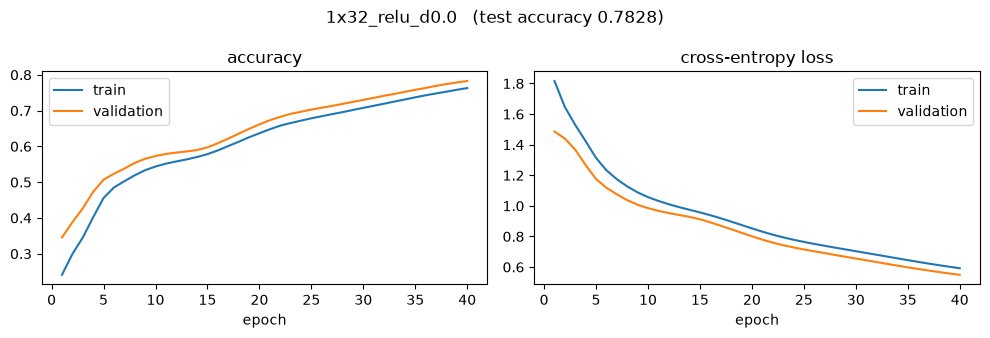

In [67]:
plot_run("1x32_relu_d0.0")

**Observations `1x32_relu_d0.0`:** Looking at the accuracy graph we can see that this model increases its accuracy as the epochs go on, and it decreases its loss, which means the model is improving. However, the accuracy is a lot lower than for the bigger networks (0.78 on the test set).

We also observe that both validation and training have an almost constant linear growth and decline respectively, and the gap between them doesn't really change, they are close and parallel to each other. So there is no overfitting, but the model is underfitting: the curves are still going up/down at epoch 40, so it never converged and more epochs would probably still help. With only 32 neurons the network also has little capacity; full_house is almost never recognised (recall 0.014).

Validation is above training the whole time. That is not a mistake: the training accuracy is an average over the epoch while the weights are still changing, and the training set is balanced (many rare, harder hands), while the validation set is mostly nothing and one_pair.

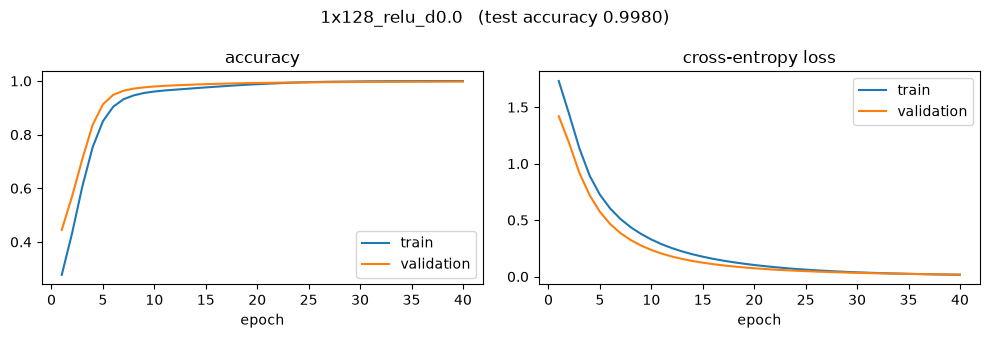

In [68]:
plot_run("1x128_relu_d0.0")

**Observations `1x128_relu_d0.0`:** From the accuracy graph, we can see that the training line is increasing just like the validation and it reaches a point where they are running on top of each other. Compared to 1x32 the growth here happens quicker.

From the cross-entropy we can see similar behaviour, the training loss gets less and less, following the validation in parallel until they kind of merge. And again the decrease happens earlier/quicker than in the model 1x32 relu.

That signifies that a wider layer (128 instead of 32 neurons) is enough to learn the rules: the network reaches 0.998 test accuracy and train and validation stay together, so there is no overfitting. Early stopping did not stop it (40 epochs), the loss was still slowly going down. The weakest class is full_house (0.88).

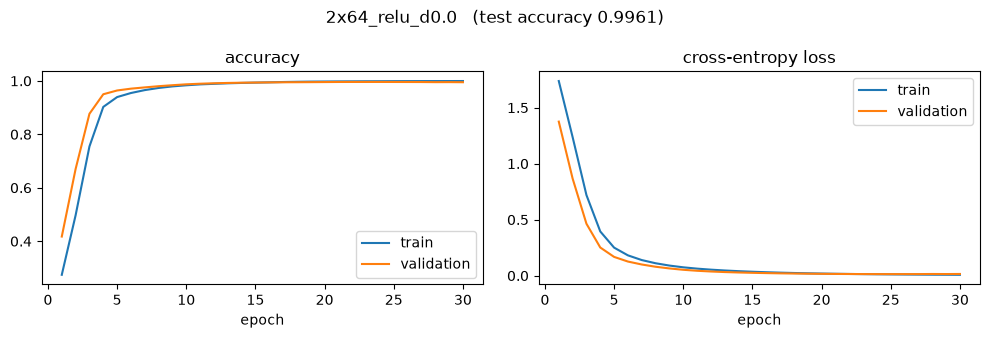

In [69]:
plot_run("2x64_relu_d0.0")

**Observations `2x64_relu_d0.0`:** This network acts similar to the previous one (1x128 relu), so a similar conclusion can be made (test accuracy 0.996), with the exception that this model stops at epoch 30: the best validation loss was at epoch 25 and it didn't improve in the next 5 epochs (patience), so early stopping ended the training and restored the weights from epoch 25. Two smaller layers give about the same result as one bigger layer with a similar number of weights (~10k vs ~12k).

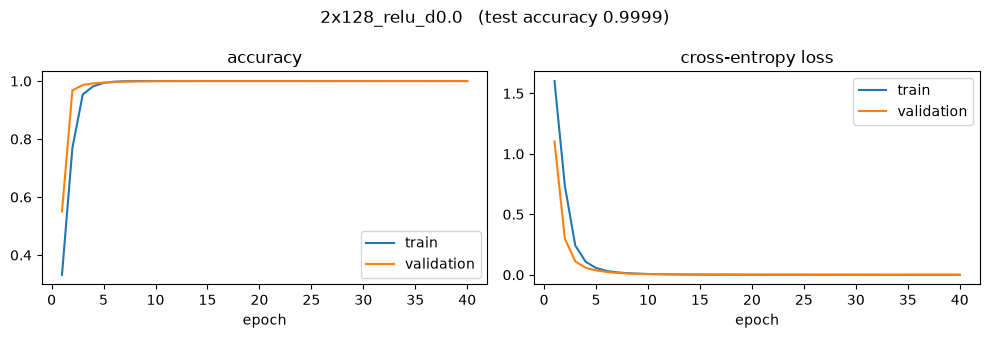

In [70]:
plot_run("2x128_relu_d0.0")

**Observations `2x128_relu_d0.0`:** The obvious difference we can see is the faster growth/decrease: validation accuracy is already ~0.97 after 2 epochs and the network reaches 0.9999 on the test set. This can be due to the fact that this neural network has 2 layers with 128 neurons, so more capacity than the previous ones. Train and validation lie on top of each other after ~5 epochs, so no overfitting. It scores 1.0 on all classes except straight_flush (see 3.4).

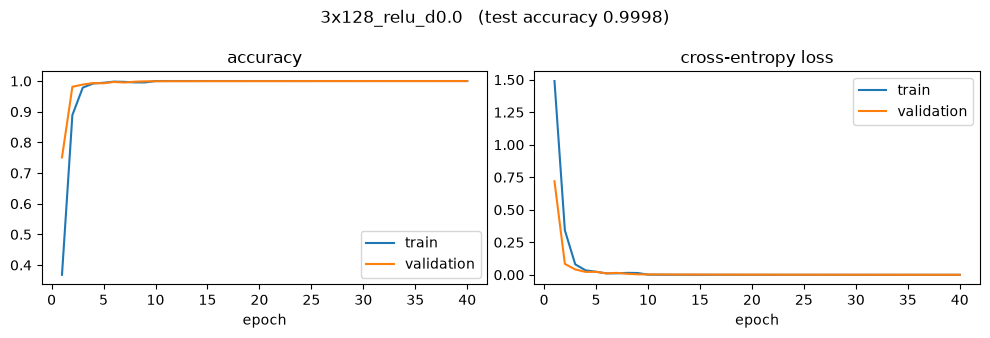

In [71]:
plot_run("3x128_relu_d0.0")

**Observations `3x128_relu_d0.0`:** Compared to the previous graphs, the validation here starts with a higher accuracy (0.75 after the first epoch) and learning is even faster: after ~3 epochs both are close to 1.0 and stay there. In the first epochs validation is above training; that is because the training accuracy is an average over the whole epoch while the weights are still changing, while the validation score is measured at the end of the epoch. After that, train and validation run on top of each other, which is a very good result: the model doesn't overfit but learns.

Similar case happens with the cross-entropy: the loss drops to almost 0 within 5 epochs. Test accuracy is 0.9998, so adding a third layer did not improve over 2x128.

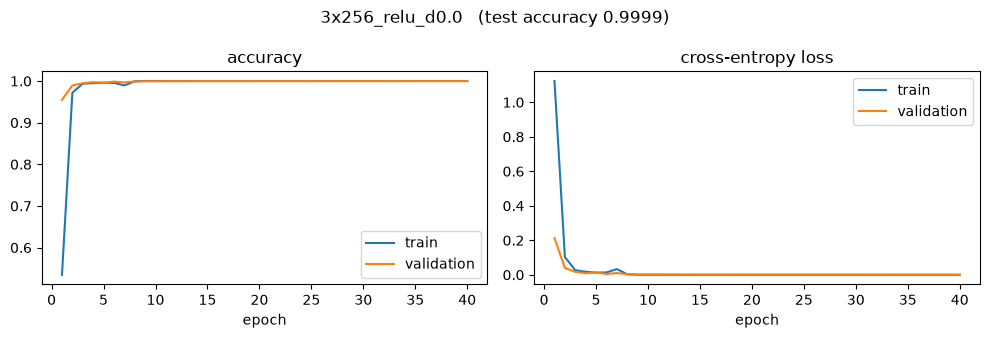

In [72]:
plot_run("3x256_relu_d0.0")

**Observations `3x256_relu_d0.0`:** In this case the validation starts with very good accuracy/loss (0.95 after the first epoch), probably because we have increased the number of neurons (256 per layer), so the network learns more per epoch. There is an interesting small negative bump in the training results around epoch 7. This is not overfitting (then validation would get worse while training gets better) and not dropout either, because this network has no dropout. It is a small instability of the optimizer: a few too-large weight updates that increase the loss for a moment, after which the training recovers in the next epoch. Test accuracy 0.9999, the same as 2x128, so the bigger network doesn't add anything here.

### 3.2 Activation function (sigmoid / tanh vs ReLU)

Two network sizes, each also trained with ReLU in 3.1 (`1x32_relu_d0.0`, `2x128_relu_d0.0`), so each row compares three activations.

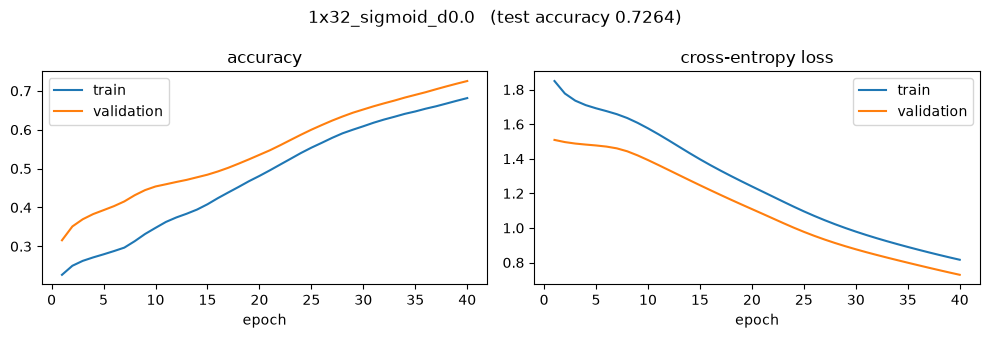

In [73]:
plot_run("1x32_sigmoid_d0.0")

**Observations `1x32_sigmoid_d0.0`:** This is the worst network of all (0.726 test accuracy). Compared to 1x32 relu (0.783) the loss goes down slower, especially in the first ~8 epochs where the curves are almost flat. Sigmoid squashes everything between 0 and 1 and its gradient is small (max 0.25), so the weights get smaller updates and learning is slower. The curves are still going up at epoch 40, so it is underfitting, like 1x32 relu. full_house is never predicted correctly (0.0).

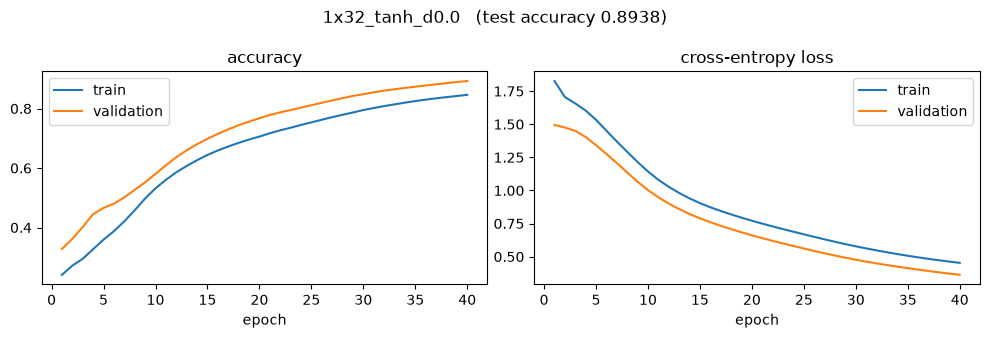

In [74]:
plot_run("1x32_tanh_d0.0")

**Observations `1x32_tanh_d0.0`:** Tanh is clearly better than both relu and sigmoid for this small network (0.894 vs 0.783 and 0.726). Tanh is centred around 0 and has a stronger gradient than sigmoid, so it learns faster. Compared with relu: with only 32 neurons, some relu neurons can "die" (output always 0), while tanh neurons always pass some signal, which may be why tanh uses the 32 neurons better. Also here the curves are still improving at epoch 40, so more epochs would help.

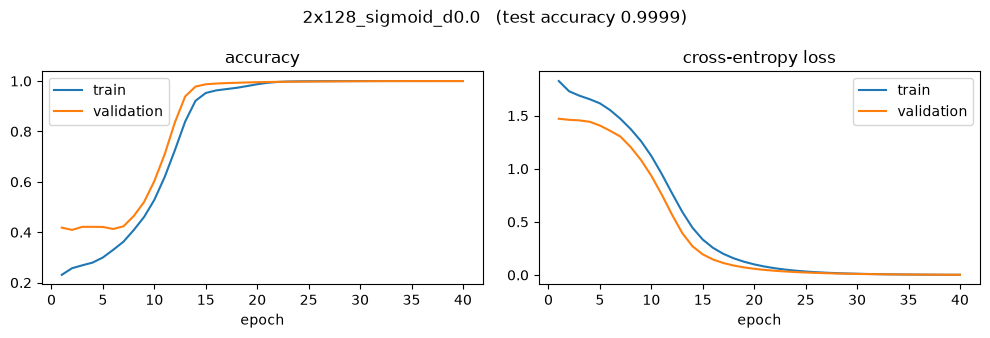

In [75]:
plot_run("2x128_sigmoid_d0.0")

**Observations `2x128_sigmoid_d0.0`:** With 2 layers of 128 neurons, sigmoid also reaches 0.9999, so with enough capacity the activation function matters less for the final result. But the graph shows the typical sigmoid behaviour: for the first ~7 epochs the validation accuracy stays flat around 0.42 (the network hardly learns), after which it suddenly increases until epoch 15. The relu and tanh versions reach the same level after ~5 epochs. Its validation loss (0.0021) is also ~10x higher than relu (0.00045) and tanh (0.00019), so it is less confident in its predictions.

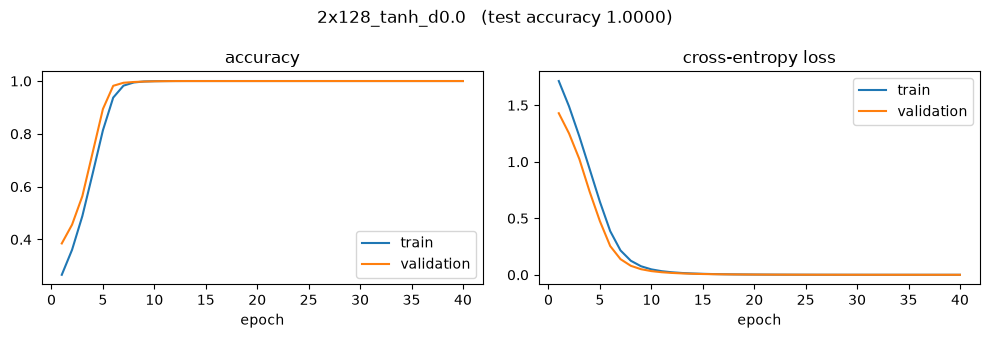

In [76]:
plot_run("2x128_tanh_d0.0")

**Observations `2x128_tanh_d0.0`:** This is the best network of all experiments: 1.0000 validation and test accuracy (0.99998, so only 3 wrong out of 153,416 test hands) and the lowest validation loss (0.00019). It learns a bit slower than 2x128 relu in the first epochs (relu reaches ~0.97 at epoch 2, tanh around epoch 6), but ends with a lower loss. Train and validation overlap, no overfitting. The only class it gets wrong is straight_flush (0 of 2 test hands), see 3.4.

### 3.3 Dropout (ReLU)

Dropout after every hidden layer; the versions without dropout are `2x128_relu_d0.0` and `3x256_relu_d0.0` in 3.1.

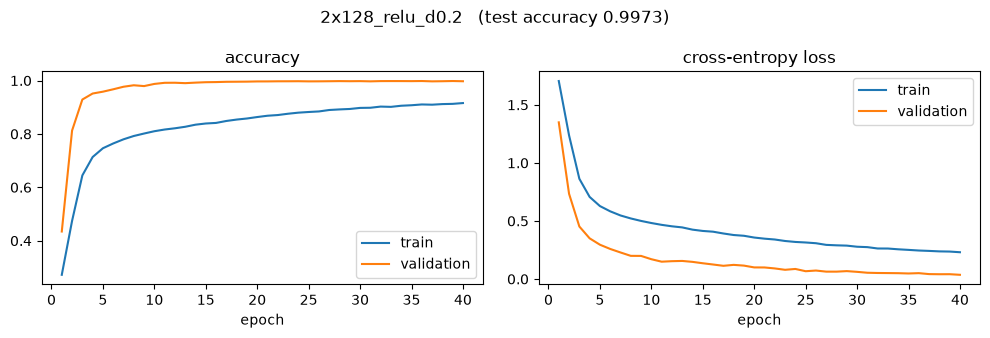

In [77]:
plot_run("2x128_relu_d0.2")

**Observations `2x128_relu_d0.2`:** With 20% dropout the training curve is clearly below validation the whole time (train ~0.91, validation ~0.997 at the end). That is because dropout is only active during training: in every batch 20% of the neurons are switched off, so the training score is measured on a "handicapped" network, while validation uses the full network. Compared to without dropout (0.9999), the test accuracy drops a bit to 0.9973 and the network learns slower; it is still improving at epoch 40. There was no overfitting to prevent in the first place, so dropout only costs performance here. full_house drops to 0.80.

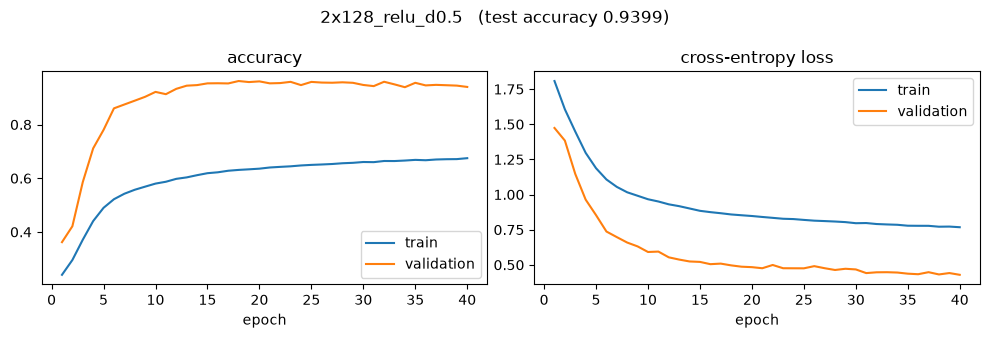

In [78]:
plot_run("2x128_relu_d0.5")

**Observations `2x128_relu_d0.5`:** With 50% dropout the effect is much stronger: training accuracy stays around 0.67 and validation around 0.94-0.95, with a lot of small ups and downs. Half of the neurons are switched off in every step, so the network effectively has too little capacity to learn the rules. The test accuracy drops to 0.94 and some classes are almost lost: two_pairs 0.39, four_of_a_kind 0.17 and full_house 0.0. So 0.5 is too much dropout for this problem.

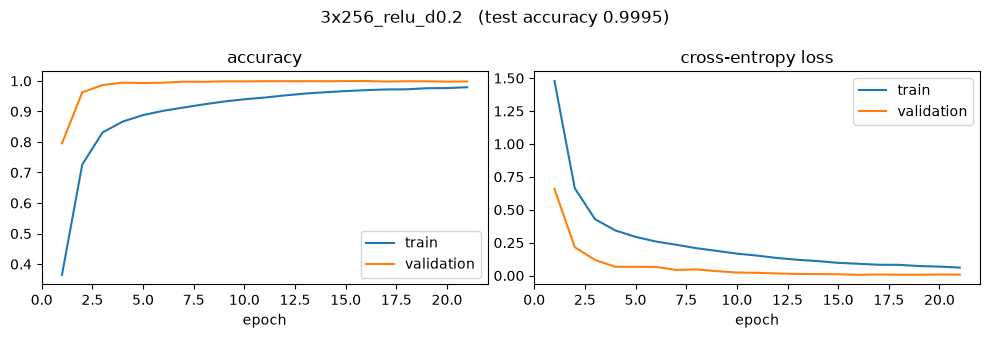

In [79]:
plot_run("3x256_relu_d0.2")

**Observations `3x256_relu_d0.2`:** This is the only dropout run where early stopping kicked in: best validation loss at epoch 16, stopped at 21. The gap between train (dropout active) and validation is again visible, but smaller than with 2x128, because 3x256 has many more neurons, so switching 20% off hurts less. Test accuracy 0.9995, a bit below the version without dropout (0.9999). It has the highest mean recall (0.993) because it got both straight flushes and the royal flush right, but those are only 3 test hands, so that is mostly luck.

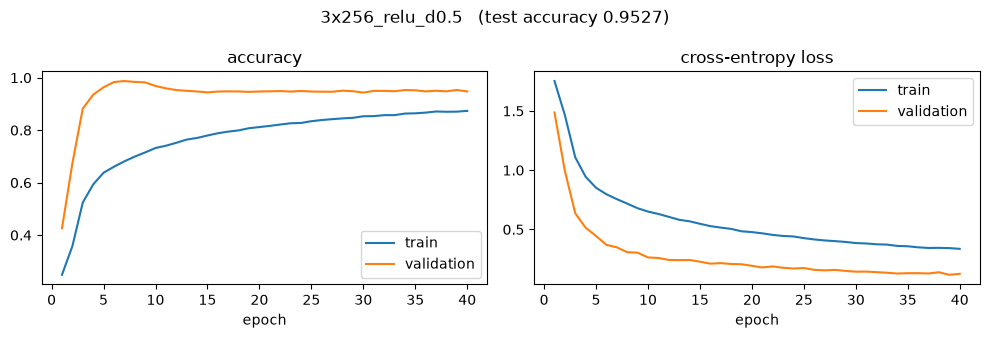

In [80]:
plot_run("3x256_relu_d0.5")

**Observations `3x256_relu_d0.5`:** Validation accuracy goes up to ~0.99 at epoch 7 and then drops back to ~0.95 and stays there, while training keeps improving slowly (0.87 at epoch 40). Interesting is that the validation loss keeps going down at the same time, so early stopping (which watches val_loss) did not stop it. Same as 2x128 with 0.5 dropout: too much regularization. The test accuracy is 0.953, and two_pairs (0.12), full_house (0.22) and four_of_a_kind (0.33) are mostly wrong. The bigger network handles 50% dropout a bit better than 2x128 (0.953 vs 0.940).

### 3.4 Performance per class (test set)

Recall per class = share of the test hands of that class that were predicted correctly. Classes with very few test hands (straight flush: 2, royal flush: 1) give unreliable numbers.

In [81]:
per_class_table = pd.concat([per_class(n) for n, *_ in EXPERIMENTS], axis=1).T
per_class_table.loc["test hands"] = np.bincount(y_test, minlength=10)
per_class_table

,nothing,one_pair,two_pairs,three_of_a_kind,straight,flush,full_house,four_of_a_kind,straight_flush,royal_flush
1x32_relu_d0.0,0.893,0.666,0.656,0.773,0.988,0.984,0.014,0.639,0.0,1.0
1x128_relu_d0.0,1.000,0.996,1.000,0.998,1.000,0.997,0.881,1.000,0.0,0.0
2x64_relu_d0.0,0.998,0.994,0.995,0.995,1.000,0.993,0.886,1.000,0.0,0.0
2x128_relu_d0.0,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.0,1.0
3x128_relu_d0.0,1.000,1.000,1.000,1.000,1.000,1.000,0.995,1.000,1.0,0.0
3x256_relu_d0.0,1.000,1.000,1.000,1.000,1.000,1.000,0.991,1.000,0.5,0.0
1x32_sigmoid_d0.0,0.900,0.540,0.645,0.513,0.893,0.990,0.000,0.361,0.0,1.0
1x32_tanh_d0.0,0.951,0.849,0.773,0.708,0.953,0.990,0.452,0.861,0.0,1.0
2x128_sigmoid_d0.0,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.0,1.0
2x128_tanh_d0.0,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.0,1.0


**Observations per class:** We can see that for the rare classes, like the royal flush (only 1 hand in the test set) and the straight flush (2 hands), the recall can only be 0, 0.5 or 1, so those numbers are mostly luck and say little about the model. The easier classes to predict are the ones that are well represented, like nothing, one/two_pairs or three_of_a_kind, and also straight and flush. The hardest class is full_house: the small networks and the 0.5-dropout networks almost never get it right (0.0-0.45), and with 0.5 dropout two_pairs and four_of_a_kind also break down.

Looking at the results 2x128 tanh seems to be performing best in almost all cases but the straight_flush; other good candidates would be 3x256 relu and 3x128 relu.

All networks use the same test set, so 2x128 tanh did have the 2 straight flushes; it predicted both of them wrong. Its test accuracy of 0.99998 means 3 wrong hands out of 153,416, so 2 of the 3 mistakes are these straight flushes. A straight flush is both a straight and a flush, so the network probably predicted one of those. The training set only has 12 unique straight flushes (copied to 2,000 by oversampling), so the network could memorise those 12 but not learn the general rule.

### 3.5 Encoding comparison: one-hot ranks vs one scaled number per rank

Same network as the best one-hot network, same split and the same balancing; only the rank encoding differs (5 one-hot suits + 5 ranks scaled to 0..1 = 25 features instead of 85).

2x128_tanh_scaled        epochs=40     82s  val_acc=0.6955  test_acc=0.6950


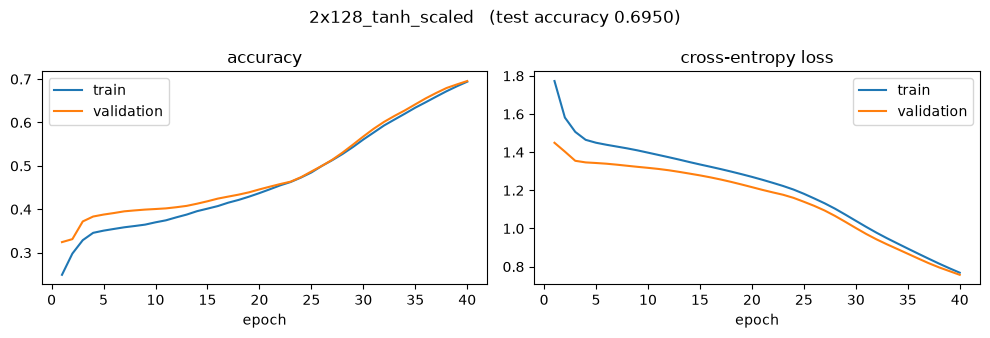

,nothing,one_pair,two_pairs,three_of_a_kind,straight,flush,full_house,four_of_a_kind,straight_flush,royal_flush
one-hot ranks,1.000,1.000,1.000,1.000,1.000,1.00,1.000,1.000,0.0,1.0
scaled ranks,0.963,0.383,0.668,0.677,0.498,0.98,0.256,0.167,0.0,0.0


In [82]:
ENC_RESULTS = Path("results_encoding"); ENC_RESULTS.mkdir(exist_ok=True)

def run_encoding(name, hidden, activation="relu", rank_encoding="scaled"):
    path = ENC_RESULTS / f"{name}.json"
    
    if path.exists():                                            # finished runs are loaded, not repeated
        result = json.loads(path.read_text()); report(result); return result
    
    Xe = encode(df, rank_encoding)
    Xb, yb = balance(Xe[idx_tr], y_tr)                           # same rows as the one-hot training set
    
    keras.utils.set_random_seed(SEED)
    model = build_model(hidden, activation, n_features=Xe.shape[1])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    t = time.perf_counter()
    
    h = model.fit(Xb, to_categorical(yb, 10), validation_data=(Xe[idx_val], Y_val), epochs=MAX_EPOCHS,
                  batch_size=BATCH, callbacks=[stop], verbose=0)
    seconds = time.perf_counter() - t
    
    test_loss, test_acc = model.evaluate(Xe[idx_test], Y_test, batch_size=4096, verbose=0)
    pred = model.predict(Xe[idx_test], batch_size=4096, verbose=0).argmax(1)
    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    best = int(np.argmin(hist["val_loss"]))
    
    result = dict(name=name, hidden=hidden, activation=activation, rank_encoding=rank_encoding,
                  epochs_run=len(hist["loss"]), best_epoch=best + 1, seconds=round(seconds, 1),
                  val_acc=hist["val_accuracy"][best], val_loss=hist["val_loss"][best],
                  test_acc=float(test_acc), test_loss=float(test_loss),
                  recall=[float((pred[y_test == c] == c).mean()) for c in range(10)], history=hist)
    
    path.write_text(json.dumps(result)); report(result)
    return result

run_encoding("2x128_tanh_scaled", [128, 128], "tanh")
plot_run("2x128_tanh_scaled", ENC_RESULTS)
pd.concat([per_class("2x128_tanh_d0.0").rename("one-hot ranks"),
           per_class("2x128_tanh_scaled", ENC_RESULTS).rename("scaled ranks")], axis=1).T

**Observations encoding:** With the ranks as one scaled number (25 features), the same 2x128 tanh network only reaches 0.695 test accuracy instead of 1.000 with one-hot ranks (85 features). The curves show it is still learning slowly at epoch 40, so more epochs would help a bit, but the difference is huge. Most poker hands depend on whether ranks are *equal* (pairs, three/four of a kind, full house) or *consecutive* (straight). With one-hot encoding, two cards with the same rank have exactly the same vector, so that is easy to see for the network. With one number, it has to learn that 0.385 and 0.385 are the same while 0.385 and 0.462 are not, which is much harder. This is visible in the per-class table: one_pair (0.38), full_house (0.26) and four_of_a_kind (0.17) drop the most, while flush, which only depends on the suits (still one-hot), stays good (0.98).

## 4. Cross-validation of the best network

In [83]:
def cross_validate(hidden, activation="relu", dropout=0.0, k=5):
    """Balance only inside each fold's training part, so duplicated rare hands never leak into the fold being scored."""
    scores = []
    
    for fold, (tr, va) in enumerate(StratifiedKFold(k, shuffle=True, random_state=SEED).split(X_tr, y_tr), 1):
        Xb, yb = balance(X_tr[tr], y_tr[tr])
        keras.utils.set_random_seed(SEED + fold)
        model = build_model(hidden, activation, dropout)
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
        
        model.fit(Xb, to_categorical(yb, 10), validation_data=(X_tr[va], to_categorical(y_tr[va], 10)),
                  epochs=MAX_EPOCHS, batch_size=BATCH, callbacks=[stop], verbose=0)
        pred = model.predict(X_tr[va], batch_size=4096, verbose=0).argmax(1)
        scores.append(float((pred == y_tr[va]).mean()))
        
        print(f"fold {fold}: accuracy {scores[-1]:.4f}")
    
    print(f"mean {np.mean(scores):.4f} +/- {np.std(scores):.4f}")
    return scores

5-fold stratified cross-validation on the (unbalanced) training part, for the network with the best validation accuracy. Each fold is balanced separately; the scored fold keeps the natural class distribution.

In [84]:
best = json.loads((RESULTS / f"{summary().loc[0, 'name']}.json").read_text())
cv_path = RESULTS.parent / "cv_result.json"                      # cached: the 5 folds take several minutes

if cv_path.exists() and json.loads(cv_path.read_text())["name"] == best["name"]:
    cv = json.loads(cv_path.read_text())
    for fold, s in enumerate(cv["scores"], 1): print(f"fold {fold}: accuracy {s:.4f}")
    print(f"mean {np.mean(cv['scores']):.4f} +/- {np.std(cv['scores']):.4f}")
else:
    cv = dict(name=best["name"], scores=cross_validate(best["hidden"], best["activation"], best["dropout"]))
    cv_path.write_text(json.dumps(cv))

print("network:", cv["name"])

fold 1: accuracy 1.0000
fold 2: accuracy 1.0000
fold 3: accuracy 1.0000
fold 4: accuracy 1.0000
fold 5: accuracy 1.0000
mean 1.0000 +/- 0.0000
network: 2x128_tanh_d0.0


**Observations cross-validation:** The best network (2x128 tanh) scores 1.0000 in all 5 folds, with a standard deviation of 0.0000. So the result does not depend on the specific train/validation split we picked: the network learned the rules, not a lucky split. Note that rounded to 4 decimals, 1.0000 can still mean a few wrong hands per fold (each fold has ~143,000 hands), and the rare classes have only 1-3 hands per fold, so the cross-validation says little about them.

## 5. Export and reload of the best network

In [85]:
best_name = summary().loc[0, "name"]                           # highest validation accuracy (ties: lowest validation loss)
keras.models.load_model(MODELS / f"{best_name}.keras").save("best_poker_model.keras")

print("exported:", best_name)

exported: 2x128_tanh_d0.0


In [86]:
# Load the exported model and evaluate it on a dataset read from file (raw hands, same columns as poker_hands.csv)
loaded = keras.models.load_model("best_poker_model.keras")
hands = pd.read_csv(TEST_FILE)
pred = loaded.predict(encode(hands), batch_size=4096, verbose=0).argmax(1)

print(f"accuracy of the loaded model on {len(hands):,} hands from {TEST_FILE}: {(pred == labels(hands)).mean():.4f}")

accuracy of the loaded model on 153,416 hands from poker_test_hands.csv: 1.0000


## 6. Conclusion

The experiments show that neural network architecture, activation function, and dropout rate influence the classification of poker hands. Larger networks generally performed better than the smallest network: 1x32 underfitted (0.78 test accuracy and still improving after 40 epochs), while every network with at least 64 neurons per layer reached more than 99.6%. Going beyond 2 layers of 128 neurons did not improve the results any further.

The activation function mattered most for the small network: with 1x32, tanh (0.89) was clearly better than relu (0.78) and sigmoid (0.73). With 2x128 all three reached ~0.9999, but sigmoid learned much slower in the first epochs and ended with a ~10x higher validation loss.

The best model depends on the evaluation metric. The two-layer network with 128 neurons per layer and tanh activation achieved the highest validation accuracy and the lowest validation loss, and is therefore the exported model. Cross-validation confirmed this result (1.0000 in all 5 folds). The three-layer network with 256 neurons per layer, ReLU activation, and 20% dropout had the highest mean recall, but this difference comes only from the 3 straight/royal flush hands in the test set, so it is not a reliable reason to prefer it.

The experiments also showed that a dropout rate of 50% reduced performance considerably (0.94-0.95), especially for two_pairs, full_house and four_of_a_kind. Since the networks without dropout did not overfit (train and validation curves overlap), there was nothing for dropout to prevent, so stronger regularization did not improve the results.

The encoding of the input was even more important than the network itself: with the ranks as one scaled number instead of one-hot, the best network dropped from 1.000 to 0.695 accuracy, because equal and consecutive ranks are much harder to detect.

Although the overall accuracy was extremely high, the dataset was highly imbalanced. The test set contained very few examples of rare hands, particularly straight flush (2) and royal flush (1). Consequently, recall scores for these classes are unstable and should not be interpreted as proof of reliable classification; even the best model got both straight flushes wrong. Evaluating per-class recall alongside accuracy is therefore essential; a confusion matrix and precision per class would be a useful addition.

Limitations: 12 of the 14 networks were still improving when they reached the maximum of 40 epochs, so the smaller networks could probably do better with more epochs. The rare classes only contain a few unique hands (6 royal flushes, 12 straight flushes in training), so oversampling repeats the same hands instead of adding new information.

Overall, the experiments demonstrate that model selection should consider both predictive performance and the distribution of the classes, rather than relying on accuracy alone.